# Read-sorting evaluation on PDX, PDXO & patient samples from Guillen et al. (2022)

## 0. Imports and paths

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import *
from helper.runtime_memory import *
from warnings import simplefilter
simplefilter("ignore")

In [2]:
data_dir = Path.cwd().parent / "data" / "guillen_2022"
rrbs_dir = data_dir / "rrbs"
rrems_dir = data_dir / "rrems"
results_dir = Path.cwd() / "results"
fig_dir = Path.cwd() / "figures" 
fig_dir_sort = fig_dir / "read_sorting"
fig_dir_sort.mkdir(exist_ok = True, parents=True)

fig_dir_time = fig_dir / "runtime_memory"
fig_dir_time.mkdir(exist_ok=True)
log_dir = Path.cwd() / "logs"

hue_order=["Xengsort", "ICRG", "bamcmp", "XenofilteR"]

## 1. Load evaluation TSVs

### RRBS

In [3]:
icrg_rrbs_mspi   = load_method(results_dir / "icrg_rrbs_mspi",   "icrg")
icrg_rrbs_mspi = split_guillen_names(icrg_rrbs_mspi, key="Sample")

xengsort_rrbs_mspi = load_method(results_dir / "xengsort_rrbs_mspi", "xengsort")
xengsort_rrbs_mspi = split_guillen_names(xengsort_rrbs_mspi, key="Sample")

sites_rrbs = xengsort_rrbs_mspi[xengsort_rrbs_mspi["Category"] == "sites"]
icrg_rrbs_mspi = pd.concat([icrg_rrbs_mspi, sites_rrbs.assign(Method="icrg")], ignore_index=True)

bamcmp_rrbs_mspi = load_method(results_dir / "bamcmp_rrbs_mspi", "bamcmp")
bamcmp_rrbs_mspi = split_guillen_names(bamcmp_rrbs_mspi, key="Sample")
bamcmp_rrbs_mspi = pd.concat([bamcmp_rrbs_mspi, sites_rrbs.assign(Method="bamcmp")], ignore_index=True)

xenofilter_rrbs_mspi = load_method(results_dir / "xenofilter_rrbs_mspi", "XenofilteR")
xenofilter_rrbs_mspi = split_guillen_names(xenofilter_rrbs_mspi, key="Sample")
xenofilter_rrbs_mspi = pd.concat([xenofilter_rrbs_mspi, sites_rrbs.assign(Method="XenofilteR")], ignore_index=True)

In [4]:
icrg_rrbs = split_guillen_names(load_method(results_dir / "icrg_rrbs", "icrg"))

xengsort_rrbs = split_guillen_names(load_method(results_dir / "xengsort_rrbs", "xengsort"))

bamcmp_rrbs = split_guillen_names(load_method(results_dir / "bamcmp_rrbs", "bamcmp"))

xenofilter_rrbs = split_guillen_names(load_method(results_dir / "xenofilter_rrbs", "XenofilteR"))


### RREMS

In [5]:

xengsort_rrems_mspi = load_method(results_dir / "xengsort_rrems_mspi", "xengsort")
xengsort_rrems_mspi["Sample"] = xengsort_rrems_mspi["Sample"].str.split("_").apply(lambda x: "_".join(x[0:2]))
xengsort_rrems_mspi["Reads"] = xengsort_rrems_mspi["Reads"] * 2
sites_rrems = xengsort_rrems_mspi[xengsort_rrems_mspi["Category"] == "sites"]

icrg_rrems_mspi   = load_method(results_dir / "icrg_rrems_mspi",   "icrg")
icrg_rrems_mspi["Sample"] = icrg_rrems_mspi["Sample"].str.split("_").apply(lambda x: "_".join(x[0:2]))
icrg_rrems_mspi = pd.concat([icrg_rrems_mspi, sites_rrems.assign(Method="icrg")], ignore_index=True)


bamcmp_rrems_mspi = load_method(results_dir / "bamcmp_rrems_mspi", "bamcmp")
bamcmp_rrems_mspi = split_guillen_names(bamcmp_rrems_mspi, key="Sample")
bamcmp_rrems_mspi = pd.concat([bamcmp_rrems_mspi, sites_rrems.assign(Method="bamcmp")], ignore_index=True)

xenofilter_rrems_mspi = load_method(results_dir / "xenofilter_rrems_mspi", "XenofilteR")
xenofilter_rrems_mspi = split_guillen_names(xenofilter_rrems_mspi, key="Sample")
xenofilter_rrems_mspi = pd.concat([xenofilter_rrems_mspi, sites_rrems.assign(Method="XenofilteR")], ignore_index=True)

In [6]:
icrg_rrems = load_method(results_dir / "icrg_rrems", "icrg")
icrg_rrems["Sample"] = icrg_rrems["Sample"].str.split("_").apply(lambda x: "_".join(x[0:2]))

xengsort_rrems = load_method(results_dir / "xengsort_rrems", "xengsort")
xengsort_rrems["Sample"] = xengsort_rrems["Sample"].str.split("_").apply(lambda x: "_".join(x[0:2]))
xengsort_rrems["Reads"] = xengsort_rrems["Reads"] * 2

bamcmp_rrems = split_guillen_names(load_method(results_dir / "bamcmp_rrems", "bamcmp"))

xenofilter_rrems = split_guillen_names(load_method(results_dir / "xenofilter_rrems", "XenofilteR"))


## 2. Read sorting outcomes per method

### RRBS MspI

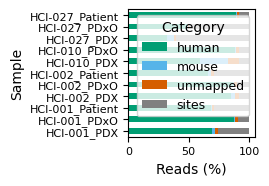

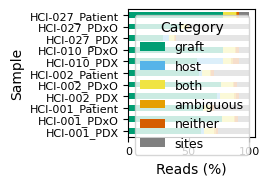

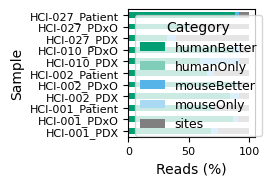

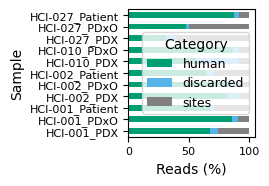

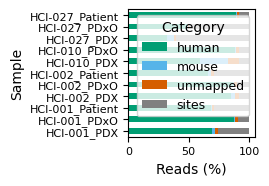

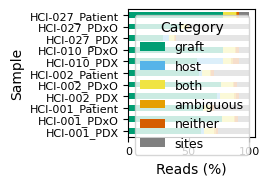

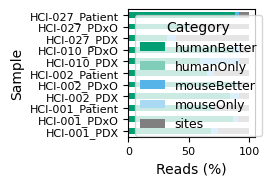

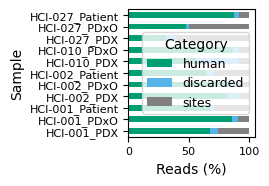

In [8]:
figsize=mm_to_inches((70, 50))

os.makedirs(fig_dir_sort / "rrbs_mspi", exist_ok = True)
for suffix in ["pdf", "png"]:
    icrg_rrbs_mspi_pivot_pct = stacked_barplot(icrg_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi" , file_name = f"icrg_rrbs_mspi_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xengsort_rrbs_mspi_pivot_pct = stacked_barplot(xengsort_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = f"xengsort_rrbs_mspi_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    bamcmp_rrbs_mspi_pivot_pct = stacked_barplot(bamcmp_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = f"bamcmp_rrbs_mspi_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    xenofilter_rrbs_mspi_pivot_pct = stacked_barplot(xenofilter_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = f"xenofilter_rrbs_mspi_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )

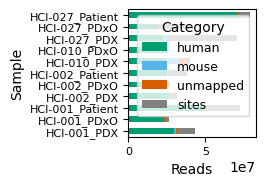

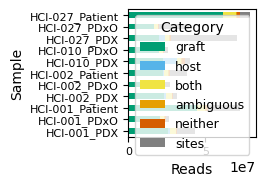

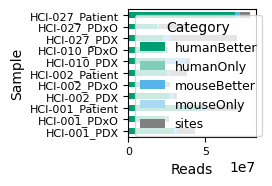

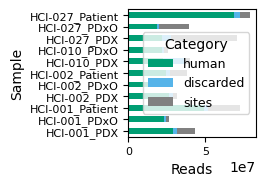

In [9]:
figsize=mm_to_inches((70, 50))

icrg_rrbs_mspi_pivot = stacked_barplot(icrg_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = "icrg_rrbs_mspi_stacked_barplot.pdf", percent=False, save = True, figsize=figsize, colors = category_colors)
xengsort_rrbs_mspi_pivot = stacked_barplot(xengsort_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = "xengsort_rrbs_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
bamcmp_rrbs_mspi_pivot = stacked_barplot(bamcmp_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = "bamcmp_rrbs_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
xenofilter_rrbs_mspi_pivot = stacked_barplot(xenofilter_rrbs_mspi, fig_dir = fig_dir_sort / "rrbs_mspi", file_name = "xenofilter_rrbs_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )



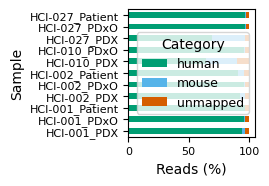

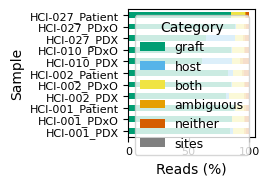

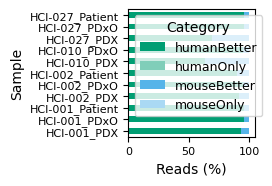

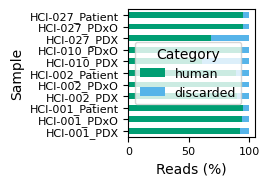

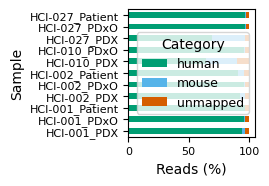

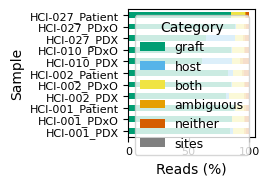

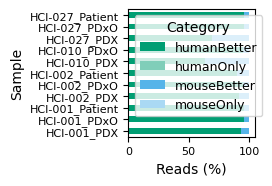

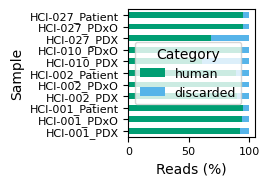

In [12]:
figsize=mm_to_inches((70, 50))
os.makedirs(fig_dir_sort / "rrbs", exist_ok  = True)
for suffix in ["pdf", "png"]:
    icrg_rrbs_pivot_pct = stacked_barplot(icrg_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = f"icrg_rrbs_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xengsort_rrbs_pivot_pct = stacked_barplot(xengsort_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = f"xengsort_rrbs_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    bamcmp_rrbs_pivot_pct = stacked_barplot(bamcmp_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = f"bamcmp_rrbs_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    xenofilter_rrbs_pivot_pct = stacked_barplot(xenofilter_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = f"xenofilter_rrbs_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )

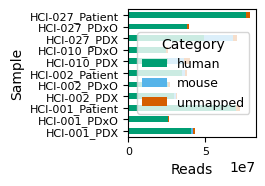

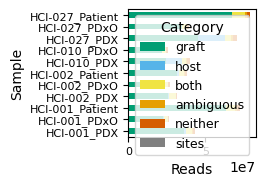

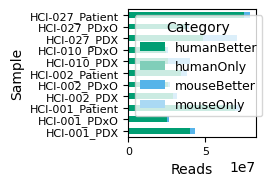

In [13]:
figsize=mm_to_inches((70, 50))
icrg_rrbs_pivot = stacked_barplot(icrg_rrbs, fig_dir = fig_dir_sort / "rrbs" , file_name = "icrg_rrbs_stacked_barplot.pdf", percent=False, save = True, figsize=figsize, colors = category_colors)
xengsort_rrbs_pivot = stacked_barplot(xengsort_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = "xengsort_rrbs_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
bamcmp_rrbs_pivot = stacked_barplot(bamcmp_rrbs, fig_dir = fig_dir_sort / "rrbs", file_name = "bamcmp_rrbs_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )

### RREMS

#### No MspI filtering


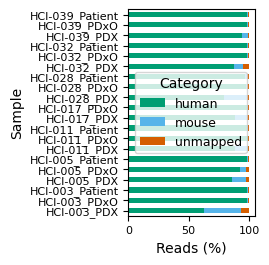

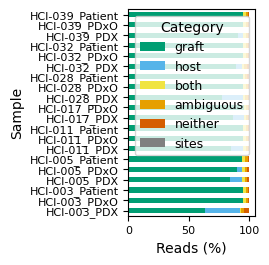

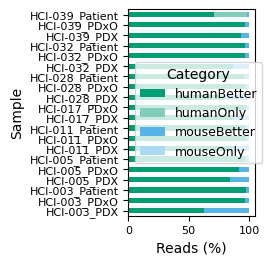

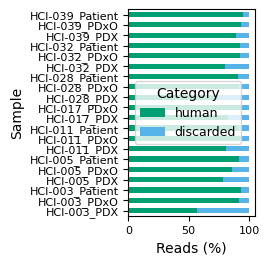

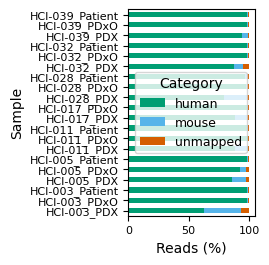

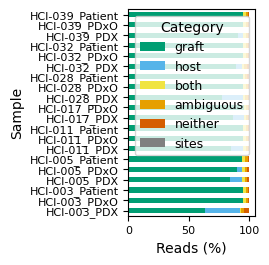

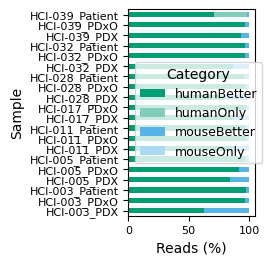

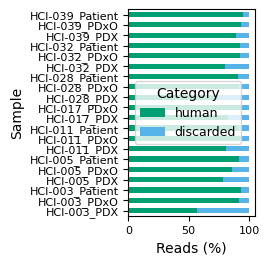

In [16]:
figsize=mm_to_inches((70, 70))
os.makedirs(fig_dir_sort / "rrems", exist_ok = True)
for suffix in ["pdf", "png"]:
    icrg_rrems_pivot_pct = stacked_barplot(icrg_rrems, fig_dir = fig_dir_sort / "rrems", file_name = f"icrg_rrems_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xengsort_rrems_pivot_pct = stacked_barplot(xengsort_rrems, fig_dir = fig_dir_sort / "rrems" , file_name = f"xengsort_rrems_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    bamcmp_rrems_pivot_pct = stacked_barplot(bamcmp_rrems, fig_dir = fig_dir_sort / "rrems", file_name = f"bamcmp_rrems_stacked_barplot_pct.{suffix}", percent = True, save=True, figsize=figsize, colors= category_colors)
    xenofilter_rrems_pivot_pct = stacked_barplot(xenofilter_rrems, fig_dir = fig_dir_sort / "rrems", file_name = f"xenofilter_rrems_stacked_barplot_pct.{suffix}", percent=True, save=True, figsize=figsize, colors= category_colors)

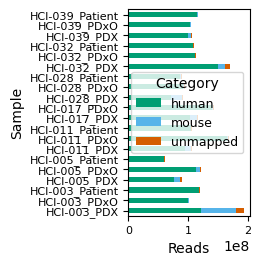

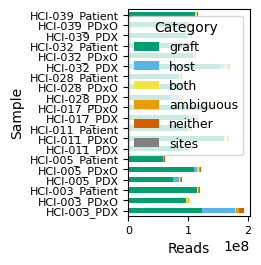

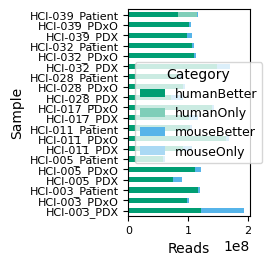

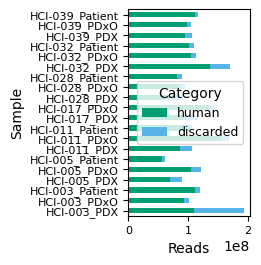

In [17]:
figsize=mm_to_inches((70, 70))
icrg_rrems_pivot = stacked_barplot(icrg_rrems, fig_dir = fig_dir_sort / "rrems", file_name = "icrg_rrems_stacked_barplot.pdf", percent=False, save = True, figsize=figsize, colors = category_colors)
xengsort_rrems_pivot = stacked_barplot(xengsort_rrems, fig_dir = fig_dir_sort / "rrems", file_name = "xengsort_rrems_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
bamcmp_rrems_pivot = stacked_barplot(bamcmp_rrems, fig_dir = fig_dir_sort / "rrems", file_name = "bamcmp_rrems_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )
xenofilter_rrems_pivot = stacked_barplot(xenofilter_rrems, fig_dir = fig_dir_sort / "rrems", file_name = "xenofilter_rrems_stacked_barplot.pdf", percent=False,save = True, figsize=figsize, colors = category_colors, )

#### Mspi Prefiltering

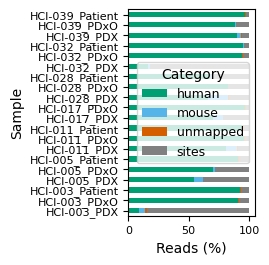

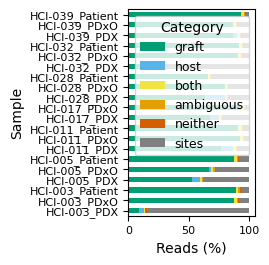

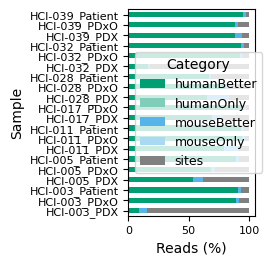

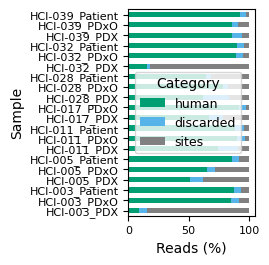

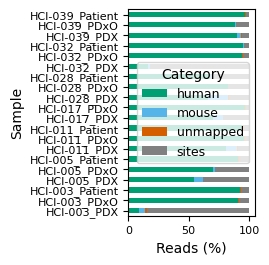

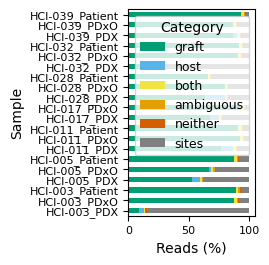

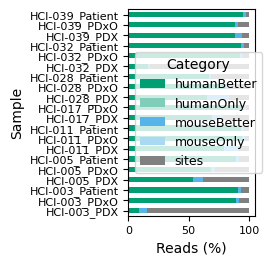

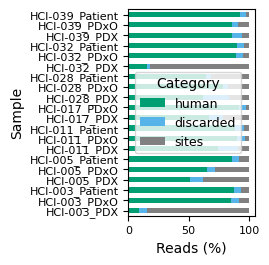

In [18]:
figsize=mm_to_inches((70, 70))
os.makedirs(fig_dir_sort / "rrems_mspi", exist_ok = True)
for suffix in ["pdf", "png"]:
    icrg_rrems_mspi_pivot_pct = stacked_barplot(icrg_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = f"icrg_rrems_mspi_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xengsort_rrems_mspi_pivot_pct = stacked_barplot(xengsort_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = f"xengsort_rrems_mspi_stacked_barplot_pct.{suffix}", percent=True,save = True, figsize=figsize, colors = category_colors, )
    bamcmp_rrems_mspi_pivot_pct = stacked_barplot(bamcmp_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = f"bamcmp_rrems_mspi_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)
    xenofilter_rrems_mspi_pivot_pct = stacked_barplot(xenofilter_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = f"xenofilter_rrems_mspi_stacked_barplot_pct.{suffix}", percent=True, save = True, figsize=figsize, colors = category_colors)

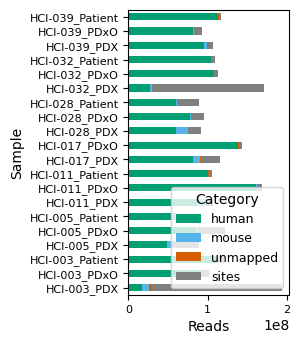

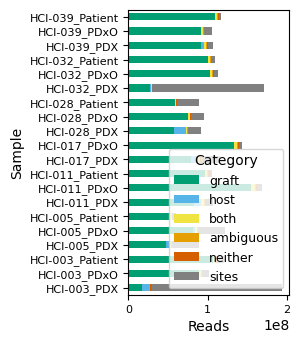

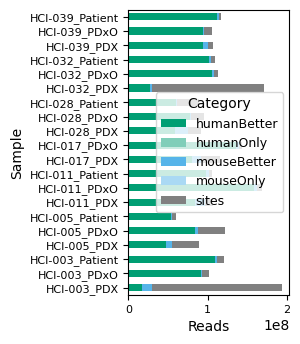

In [20]:
icrg_rrems_mspi_pivot = stacked_barplot(icrg_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = "icrg_rrems_mspi_stacked_barplot.pdf", percent=False, save = True, figsize=mm_to_inches((80, 90)), colors = category_colors)
xengsort_rrems_mspi_pivot = stacked_barplot(xengsort_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = "xengsort_rrems_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=mm_to_inches((80, 90)), colors = category_colors, )
bamcmp_rrems_mspi_pivot = stacked_barplot(bamcmp_rrems_mspi, fig_dir = fig_dir_sort / "rrems_mspi", file_name = "bamcmp_rrems_mspi_stacked_barplot.pdf", percent=False,save = True, figsize=mm_to_inches((80, 90)), colors = category_colors, )

## 3. Xengsort output overview over PDX samples

In [21]:
xengsort_rrems_pdx = xengsort_rrems[xengsort_rrems["Sample"].str.split("_").apply(lambda x: x[1] == "PDX")]
xengsort_rrbs_pdx = xengsort_rrbs[xengsort_rrbs["Sample"].str.split("_").apply(lambda x: x[1] == "PDX")]

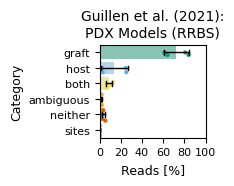

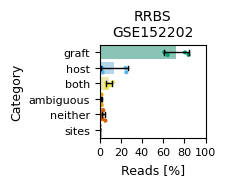

In [25]:
df_xengsort_rrbs_pdx = plot_xengsort_summary(xengsort_rrbs_pdx,percent=True, figsize=mm_to_inches((60, 50)), xticks = [0, 20, 40, 60, 80, 100], size=3, legend=False, save=True, figure_dir=fig_dir_sort, file_name="xengsort_rrbs_pdx_summary.pdf", title="Guillen et al. (2021):\nPDX Models (RRBS)")
plot_xengsort_summary(xengsort_rrbs_pdx,percent=True, figsize=mm_to_inches((60, 50)), xticks = [0, 20, 40, 60, 80, 100], size=3, legend=False, save=True, figure_dir=fig_dir_sort, file_name="xengsort_rrbs_pdx_summary.png", title="RRBS\nGSE152202");

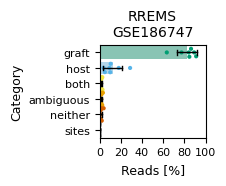

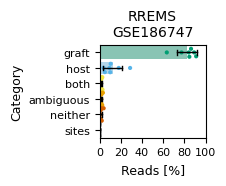

In [26]:
df_xengsort_rrems_pdx = plot_xengsort_summary(xengsort_rrems_pdx,percent=True, figsize=mm_to_inches((60, 50)), legend=False, xticks = [0, 20, 40, 60, 80, 100], save=True, figure_dir=fig_dir_sort, file_name="xengsort_rrems_pdx_summary.pdf", title="RREMS\nGSE186747", size = 3)
plot_xengsort_summary(xengsort_rrems_pdx,percent=True, figsize=mm_to_inches((60, 50)), legend=False, xticks = [0, 20, 40, 60, 80, 100], save=True, figure_dir=fig_dir_sort, file_name="xengsort_rrems_pdx_summary.png", title="RREMS\nGSE186747", size = 3);

## 4. Runtime and memory

### RRBS


####  Sorting runtime & memory

In [27]:
sorting_rrbs_xengsort = parse_lsf_logs(log_dir, method="Xengsort", pattern="xengsort_rrbs*.out")
# Strip RRBS_ prefix and trailing _0 to match xengsort evaluation sample names
sorting_rrbs_xengsort["sample"] = sorting_rrbs_xengsort["sample"].str.replace(r"^RRBS_", "", regex=True)
sorting_rrbs_xengsort.drop("replicate", axis =1, inplace=True)

sorting_rrbs_xengsort1, sorting_rrbs_xengsort_mspi = [split_guillen_names(df, key="sample") for df in split_runmem(sorting_rrbs_xengsort)]

In [28]:
sorting_rrbs_xengsort1

,sample,realtime_s,peak_rss_mb,method
0,HCI-001_PDX,168.0,40853.0,Xengsort
1,HCI-001_PDxO,141.0,40846.0,Xengsort
2,HCI-001_Patient,211.0,40852.0,Xengsort
3,HCI-002_PDX,151.0,40846.0,Xengsort
4,HCI-002_PDxO,142.0,40850.0,Xengsort
5,HCI-002_Patient,157.0,40844.0,Xengsort
6,HCI-010_PDX,163.0,40848.0,Xengsort
7,HCI-010_PDxO,224.0,40845.0,Xengsort
8,HCI-027_PDX,393.0,40831.0,Xengsort
9,HCI-027_PDxO,336.0,40814.0,Xengsort


In [30]:
sorting_bamcmp = parse_lsf_logs(log_dir, method="bamcmp", pattern="guillen_bamcmp*.out")
sorting_rrbs_bamcmp = sorting_bamcmp[sorting_bamcmp["sample"].str.contains("assay: rrbs")]
sorting_rrbs_bamcmp.drop("replicate", axis =1, inplace=True)

sorting_rrbs_bamcmp1, sorting_rrbs_bamcmp_mspi = [split_guillen_names(df, key="sample") for df in split_runmem(sorting_rrbs_bamcmp)]        

In [31]:
sorting_rrbs_xenofilter = parse_lsf_logs(log_dir, method="XenofilteR", pattern="xenofilter_rrbs_*.out")
sorting_rrbs_xenofilter.drop("replicate", axis =1, inplace=True)
sorting_rrbs_xenofilter1 = split_guillen_names(sorting_rrbs_xenofilter, key="sample")
sorting_rrbs_xenofilter_mspi = parse_lsf_logs(log_dir, method="XenofilteR", pattern="xenofilter_rrbs_mspi*.out")
sorting_rrbs_xenofilter_mspi.drop("replicate", axis =1, inplace=True)


In [33]:
sorting_rrbs = pd.concat([sorting_rrbs_xengsort1, sorting_rrbs_bamcmp1, sorting_rrbs_xenofilter], ignore_index=True)
sorting_rrbs = transform_runmem(sorting_rrbs)


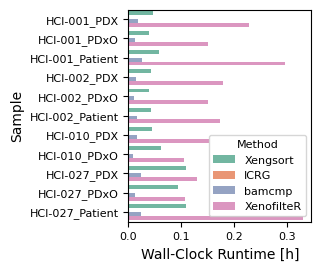

In [34]:
ax, pos = barplot_runmem(sorting_rrbs, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((60, 70)), legend=True, save=True, fig_dir = fig_dir_time, file_name = "barplot_xengsort_rrbs_realtime.pdf")


#### Alignments Runtime and Memory

In [35]:
pipelines_rrbs = {
    "ICRG":       ["pipeline_icrg"],
    "Xengsort":   ["pipeline_xengsort"],
    "bamcmp":     ["pipeline_mouse", "pipeline_human"],
    "XenofilteR": ["pipeline_mouse", "pipeline_human"],
}

pipelines_rrbs_mspi = {
    "ICRG":       ["pipeline_icrg_mspi"],
    "Xengsort":   ["pipeline_xengsort_mspi"],
    "bamcmp":     ["pipeline_mouse_mspi", "pipeline_human_mspi"],
    "XenofilteR": ["pipeline_mouse_mspi", "pipeline_human_mspi"],
}

In [36]:
alignments_rrbs = process_nfcore_traces(rrbs_dir , pipeline_method_map=pipelines_rrbs)
alignments_rrbs = transform_runmem(alignments_rrbs)
alignments_rrbs = split_guillen_names(alignments_rrbs, key="sample")

alignments_rrbs_mspi = process_nfcore_traces(rrbs_dir , pipeline_method_map=pipelines_rrbs_mspi)
alignments_rrbs_mspi = transform_runmem(alignments_rrbs_mspi)
alignments_rrbs_mspi = split_guillen_names(alignments_rrbs_mspi, key="sample")

#### No MspI Filtering

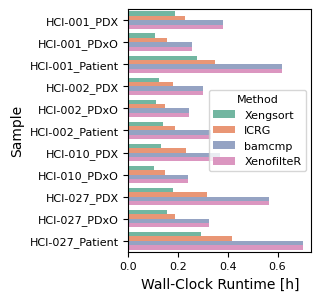

In [37]:
ax, pos = barplot_runmem(alignments_rrbs, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((60, 80)), legend=True, save=True, fig_dir = fig_dir_time, file_name = "barplot_alignment_rrbs_realtime.pdf")

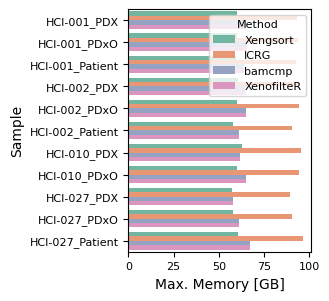

In [38]:
ax, pos = barplot_runmem(alignments_rrbs, y="peak_rss_gb", x="sample", xlabel="Max. Memory [GB]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((60, 80)), legend=True, save=True, fig_dir = fig_dir_time, file_name = "barplot_alignment_rrbs_maxmem.pdf")

### Sorting + Alignment: Runtime and Memory

In [40]:
concat_rrbs = pd.concat([alignments_rrbs, sorting_rrbs], ignore_index = True)


In [42]:
final_rrbs = (
    concat_rrbs
    .groupby(["sample", "method"], as_index=False)
    .agg(realtime_s=("realtime_s", "sum"), peak_rss_mb=("peak_rss_mb", "max"))
)
final_rrbs["realtime_h"]  = final_rrbs["realtime_s"] / 3600
final_rrbs["peak_rss_gb"] = final_rrbs["peak_rss_mb"] / 1000

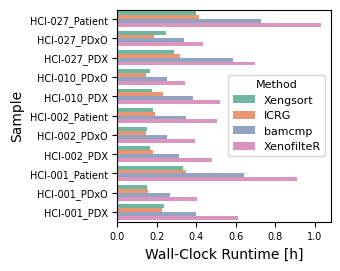

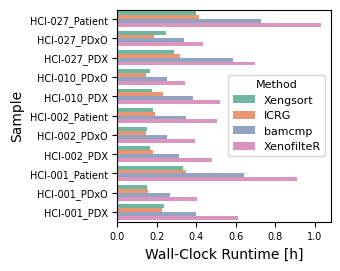

In [43]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_rrbs, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, xtick_fs=7, ytick_fs=7, reverse_order = True,
                figsize=mm_to_inches((70, 70)), legend=True, save=True, fig_dir = fig_dir_time, file_name = f"barplot_final_rrbs_realtime.{suffix}")


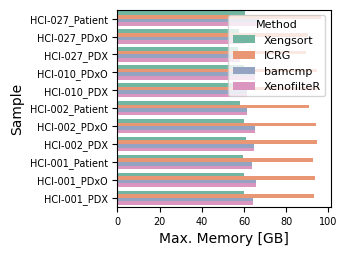

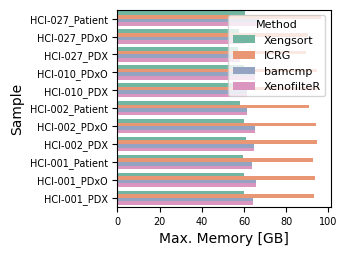

In [44]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_rrbs, y="peak_rss_gb", x="sample", xlabel="Max. Memory [GB]", ylabel="Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, ytick_fs=7, xtick_fs = 7, reverse_order =True,
                figsize=mm_to_inches((70, 65)), legend=True, save=True, fig_dir = fig_dir_time, file_name = f"barplot_final_rrbs_maxmemory.{suffix}")


### RREMS

In [46]:
sorting_rrems_xengsort = parse_lsf_logs(log_dir, method="Xengsort", pattern="xengsort_rrems*.out")

sorting_rrems_xengsort["sample"] = sorting_rrems_xengsort["sample"].str.replace(r"^RRBS_", "", regex=True)
sorting_rrems_xengsort.drop("replicate", axis =1, inplace=True)
sorting_rrems_xengsort1, sorting_rrems_xengsort_mspi = [split_guillen_names(df, key="sample") for df in split_runmem(sorting_rrems_xengsort)]


In [47]:
sorting_rrems_xengsort = parse_lsf_logs(log_dir, method="Xengsort", pattern="xengsort_rrems*.out")

In [48]:
sorting_rrems_bamcmp = sorting_bamcmp[sorting_bamcmp["sample"].str.contains("assay: rrems")]
sorting_rrems_bamcmp1, sorting_rrems_bamcmp_mspi = [split_guillen_names(df, key="sample") for df in split_runmem(sorting_rrems_bamcmp)]  

In [49]:
sorting_rrems_xenofilter = parse_lsf_logs(log_dir, method="XenofilteR", pattern="xenofilter_rrems_*.out")
sorting_rrems_xenofilter.drop("replicate", axis =1, inplace=True)
sorting_rrems_xenofilter1 = split_guillen_names(sorting_rrems_xenofilter, key="sample")
sorting_rrems_xenofilter_mspi = parse_lsf_logs(log_dir, method="XenofilteR", pattern="xenofilter_rrems_mspi*.out")
sorting_rrems_xenofilter_mspi.drop("replicate", axis =1, inplace=True)


In [50]:
sorting_rrems = pd.concat([sorting_rrems_xengsort1, sorting_rrems_bamcmp1, sorting_rrems_xenofilter1], ignore_index=True)
sorting_rrems = transform_runmem(sorting_rrems)

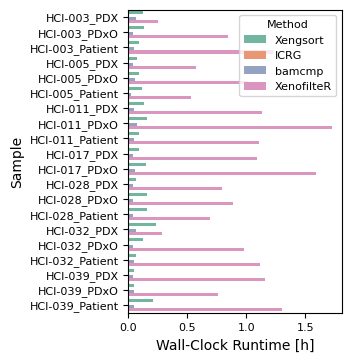

In [51]:
ax, pos = barplot_runmem(sorting_rrems, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
               hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True,
               figsize=mm_to_inches((70, 100)), legend=True, save=True, fig_dir = fig_dir_time, file_name = "barplot_xengsort_rrems_realtime.pdf")


#### Alignment

In [52]:
pipelines_rrems = {
    "ICRG":       ["pipeline_icrg"],
    "Xengsort":   ["pipeline_xengsort"],
    "bamcmp":     ["pipeline_mouse", "pipeline_human"],
    "XenofilteR": ["pipeline_mouse", "pipeline_human"],
}

pipelines_rrems_mspi = {
    "ICRG":       ["pipeline_icrg_mspi"],
    "Xengsort":   ["pipeline_xengsort_mspi"],
    "bamcmp":     ["pipeline_mouse_mspi", "pipeline_human_mspi"],
    "XenofilteR": ["pipeline_mouse_mspi", "pipeline_human_mspi"],
}

In [53]:
alignments_rrems = process_nfcore_traces(rrems_dir , pipeline_method_map=pipelines_rrems)
alignments_rrems = transform_runmem(alignments_rrems)
alignments_rrems = split_guillen_names(alignments_rrems, key="sample")

alignments_rrems_mspi = process_nfcore_traces(rrems_dir , pipeline_method_map=pipelines_rrems_mspi)
alignments_rrems_mspi = transform_runmem(alignments_rrems_mspi)
alignments_rrems_mspi = split_guillen_names(alignments_rrems_mspi, key="sample")

#### Sorting + Alignment

In [56]:
concat_rrems = pd.concat([alignments_rrems, sorting_rrems], ignore_index = True)

In [57]:
final_rrems = (
    concat_rrems
    .groupby(["sample", "method"], as_index=False)
    .agg(realtime_s=("realtime_s", "sum"), peak_rss_mb=("peak_rss_mb", "max"))
)
final_rrems["realtime_h"]  = final_rrems["realtime_s"] / 3600
final_rrems["peak_rss_gb"] = final_rrems["peak_rss_mb"] / 1000


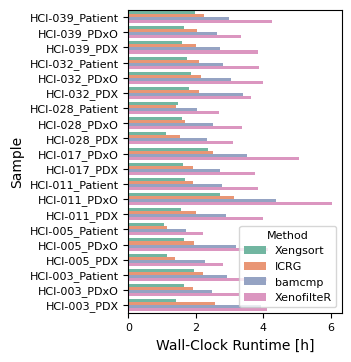

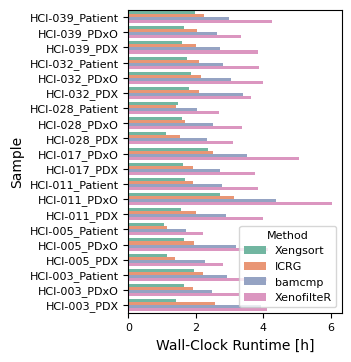

In [58]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_rrems, y="realtime_h", x="sample", xlabel="Wall-Clock Runtime [h]", ylabel="Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, xtick_fs=8, ytick_fs=8, reverse_order = True,
                figsize=mm_to_inches((70, 100)), legend=True, save=True, fig_dir = fig_dir_time, file_name = f"barplot_final_rrems_realtime.{suffix}")


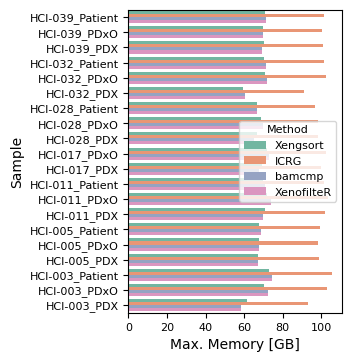

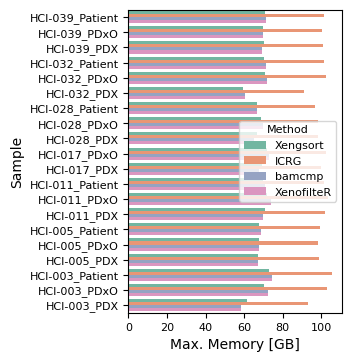

In [59]:
for suffix in ["pdf", "png"]:
    ax, pos = barplot_runmem(final_rrems, y="peak_rss_gb", x="sample", xlabel="Max. Memory [GB]", ylabel="Sample",
                hue="method", hue_order=hue_order, errorbar="sd", xtick_rotation = 0, horizontal = True, xtick_fs=8, ytick_fs=8, reverse_order = True,
                figsize=mm_to_inches((70, 100)), legend=True, save=True, fig_dir = fig_dir_time, file_name = f"barplot_final_rrems_maxmem.{suffix}")
